# 02 · Preprocessing and Feature Engineering
### IT3091 Machine Learning · Group 2026-AI-42 · Bank Marketing: ranking clients for a term-deposit telemarketing campaign

**Led by:** Preprocessing & feature-engineering lead  |  **Input:** the findings of `01_eda.ipynb`  |  **Output:** one leakage-safe pipeline, `src.features.preprocessing.build_pipeline`, used unchanged by notebooks 03-08

---

## What this notebook has to settle
EDA found six data issues. Each becomes a **decision** here, written in the same four parts: **Issue → Options considered → Evidence → Decision**. Where a choice can be tested cheaply, it is *tested* (with a rule stated before the result is seen) instead of argued.

| Section | Issue from EDA | Decision made here |
|---|---|---|
| 3 | Duplicates, `unknown` labels, `pdays = 999`, ordinal education | cleaning and encoding rules |
| 4 | Skewed `campaign`, different numeric scales | transforms and scaling |
| 5 | Drift over time | chronological train / pilot / test split |
| 6 | Extra features promised in the proposal | adopt a feature family only if it helps out of time |
| 7 | `duration` and `campaign` carry outcome information | leakage guard and a realism check |
| 8 | Everything above | the final pipeline, with automatic checks |

### The one rule that governs the whole notebook: no leakage
**Anything that learns from data** (a median to fill gaps, a mean and standard deviation to scale, the list of categories to encode) **must be learned from the training rows only.** If it is learned from the whole file, information about the future leaks into the training step and every score looks better than reality. We enforce this structurally: every learned step sits *inside* a scikit-learn `Pipeline`, which is re-fitted on the training part of each fold. Steps that use fixed constants and no data (re-coding `999`, mapping education to a number, taking a logarithm) are safe to apply row by row.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # lets the notebook import the project code in src/
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.config import *
from src.data.loading import load_raw
from src.data.splits import deduplicate, chronological_split, describe_split
from src.data import eda_checks as ec
from src.features.preprocessing import (add_features, add_features_v2, active_columns, build_pipeline, family_pipeline,
                                        feature_log, FE_GROUPS, NUM_COLS, CAT_COLS)
from src.evaluation.metrics import cv_eval, fc_eval, summarise
from src.models.candidates import hgb
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170, "display.max_colwidth", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FAST = False      # True = fewer cross-validation folds for a quick dry run (numbers then differ slightly)

---
## 2 · The preprocessing blueprint

The order of operations matters, because some steps need the output of the previous one. Everything from the `ColumnTransformer` onward is fitted on training data only.

```
raw row
  │  (drop exact duplicates, keep file order)                                  ← before the split, uses no statistics
  ▼
add_features   ── pdays 999 → flag + 0  ·  education → ordinal  ·  log(1+campaign)   ← constants only, cannot leak
  │
  ▼  ColumnTransformer  (fitted on TRAINING rows only)
  ├── numeric columns  → median imputation (+ missing-indicator) → [standard scaling]
  └── categorical cols → one-hot encoding (rare levels < 20 rows grouped, unseen levels ignored)
  │
  ▼  (optional) resampler: SMOTE / SMOTE-Tomek     ← only ever sees the training part of a fold (notebook 04)
  ▼
model
```
Columns **never** entering the model: `duration` (class C in the EDA audit) and, by default, the five macro indicators (calendar proxies).

---
## 3 · Cleaning and encoding decisions

### 3.1 Duplicates
**Issue.** Twelve exact duplicate rows. **Options:** keep / drop. **Evidence and decision:** a repeated row in both train and test would be "remembered" rather than predicted; they are a negligible share of the file, so dropping costs nothing. We keep the **first** occurrence and the **original order**, because file order is time order.

In [2]:
raw = load_raw()
df = deduplicate(raw)
kept_positions = raw.drop_duplicates().index
print(f"Rows before: {len(raw):,} | after: {len(df):,} | removed: {len(raw) - len(df)}")
print("Original order preserved (kept row positions still increase):", bool(kept_positions.is_monotonic_increasing))

Loading local file: bank-additional-full.csv
Rows before: 41,188 | after: 41,176 | removed: 12
Original order preserved (kept row positions still increase): True


### 3.2 Hidden missing values (`unknown`)
**Issue.** `unknown` replaces a missing answer in `job`, `marital`, `default`, `housing`, `loan` and `education` (EDA 3.3).

| Option | What it does | Risk |
|---|---|---|
| **A. Own category** | `unknown` becomes one more level to one-hot encode | adds a few columns; none |
| **B. Mode imputation** | replace `unknown` by the most common level of the column (learned on the training fold) | invents an answer; erases the fact that it was missing |
| **C. Drop the rows** | remove every row with any `unknown` | loses a large share of the data (`default` alone is about a fifth of the rows) and changes who is in the data |

Option C is ruled out on volume alone. A and B are tested below on the same forward-chaining folds, with a rule fixed in advance: **B replaces A only if it is better in at least 3 of 4 folds.**

In [3]:
sp = chronological_split(df)
X_train, y_train, X_test, y_test = sp["X_train"], sp["y_train"], sp["X_test"], sp["y_test"]

UNK_COLS = ["job", "marital", "default", "housing", "loan"]
def fe_unknown_to_nan(X):
    X = add_features(X)
    for c in UNK_COLS:
        X[c] = X[c].astype(object).where(X[c] != "unknown", np.nan)
    return X

def pipe_mode_imputation(model, scale):
    num, cat = active_columns()
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    cat_steps = [("imp", SimpleImputer(strategy="most_frequent")),
                 ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False))]
    pre = ColumnTransformer([("num", Pipeline(num_steps), num), ("cat", Pipeline(cat_steps), cat)])
    return Pipeline([("fe", FunctionTransformer(fe_unknown_to_nan)), ("prep", pre), ("model", model)])

TEST_MODELS = {"Logistic regression": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True),
               "Hist. gradient boosting": (lambda: hgb(learning_rate=0.06, max_iter=200, class_weight="balanced"), False)}
rows = []
for mname, (factory, scale) in TEST_MODELS.items():
    a = fc_eval(build_pipeline(factory(), scale=scale), X_train, y_train)
    b = fc_eval(pipe_mode_imputation(factory(), scale), X_train, y_train)
    d = b["pr_auc"] - a["pr_auc"]
    rows.append(dict(model=mname, pr_auc_own_category=a["pr_auc"].mean(), pr_auc_mode_imputation=b["pr_auc"].mean(),
                     mode_minus_own=d.mean(), folds_where_mode_better=f"{int((d > 0).sum())}/{len(d)}",
                     verdict="switch to mode imputation" if (d > 0).sum() >= 3 else "keep 'unknown' as its own category"))
unk_test = pd.DataFrame(rows).set_index("model")
display(unk_test.round(4))

,pr_auc_own_category,pr_auc_mode_imputation,mode_minus_own,folds_where_mode_better,verdict
model,,,,,
Logistic regression,0.098,0.099,0.001,2/4,keep 'unknown' as its own category
Hist. gradient boosting,0.088,0.086,-0.001,0/4,keep 'unknown' as its own category


**Decision.** Unless the table says otherwise, **`unknown` stays its own category (option A)**. It is simple, keeps all rows, and lets the model learn from the fact that an answer was missing. If the two options are within noise, the simpler, information-preserving one wins.

**Education is the one exception.** It has a natural order, so it is converted to a number (illiterate = 0 … university degree = 6). `unknown` cannot be placed on that scale, so it becomes a true missing value, filled with the **training** median inside the pipeline, and a **missing-indicator column** records which rows were filled, so no information is lost.

In [4]:
demo = add_features(df)
print("Education before and after the ordinal mapping:")
display(pd.crosstab(demo["education"], demo["education_ord"].fillna(-1).astype(int).replace({-1: "NaN (unknown)"}), margins=True))

Education before and after the ordinal mapping:


education_ord,0,1,2,3,4,5,6,NaN (unknown),All
education,,,,,,,,,
basic.4y,0,4176,0,0,0,0,0,0,4176
basic.6y,0,0,2291,0,0,0,0,0,2291
basic.9y,0,0,0,6045,0,0,0,0,6045
high.school,0,0,0,0,9512,0,0,0,9512
illiterate,18,0,0,0,0,0,0,0,18
professional.course,0,0,0,0,0,5240,0,0,5240
university.degree,0,0,0,0,0,0,12164,0,12164
unknown,0,0,0,0,0,0,0,1730,1730
All,18,4176,2291,6045,9512,5240,12164,1730,41176


### 3.3 The placeholder `pdays = 999`
**Issue.** `999` means "never contacted", not "999 days". **Options:** leave as is / set to missing and impute / flag + replace. **Decision: flag + replace by 0** (`was_contacted_before`, `pdays = 0`). Leaving 999 would tell a linear model that never-contacted clients were last contacted an enormous time ago. Imputing a median would invent a contact that never happened. The flag preserves the information exactly, and the zero is harmless because the flag already separates the two groups.

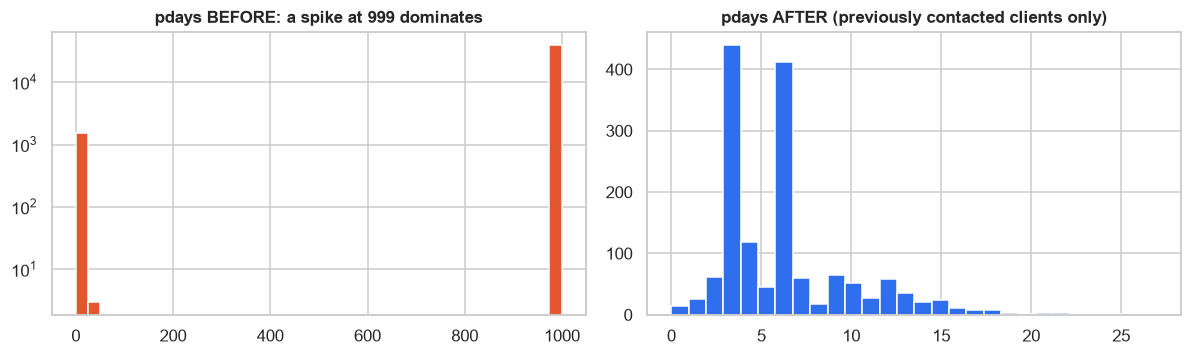

was_contacted_before = 1 for 1,515 rows (3.68%); pdays after re-coding runs 0 to 27.


In [5]:
fx = add_features(df)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df["pdays"], bins=40, color=C_WARN); ax[0].set_title("pdays BEFORE: a spike at 999 dominates"); ax[0].set_yscale("log")
ax[1].hist(fx.loc[fx["was_contacted_before"] == 1, "pdays"], bins=28, color=C_MAIN); ax[1].set_title("pdays AFTER (previously contacted clients only)")
plt.tight_layout(); save_fig("prep_pdays")
print(f"was_contacted_before = 1 for {int(fx['was_contacted_before'].sum()):,} rows ({100 * fx['was_contacted_before'].mean():.2f}%); "
      f"pdays after re-coding runs {fx['pdays'].min()} to {fx['pdays'].max()}.")

---
## 4 · Skew and scale

### 4.1 `campaign`: a long right tail
**Options:** leave / clip at a cap / log transform. Clipping discards the difference between 10 and 50 calls; a log keeps the order and compresses the tail. **Decision: keep `campaign` and add `campaign_log = log(1 + campaign)`.** Tree models ignore monotone transforms, so the extra column is free for them and helps linear and neural models.

Skewness of campaign: 4.76  ->  of log(1 + campaign): 1.35  (0 = symmetric)


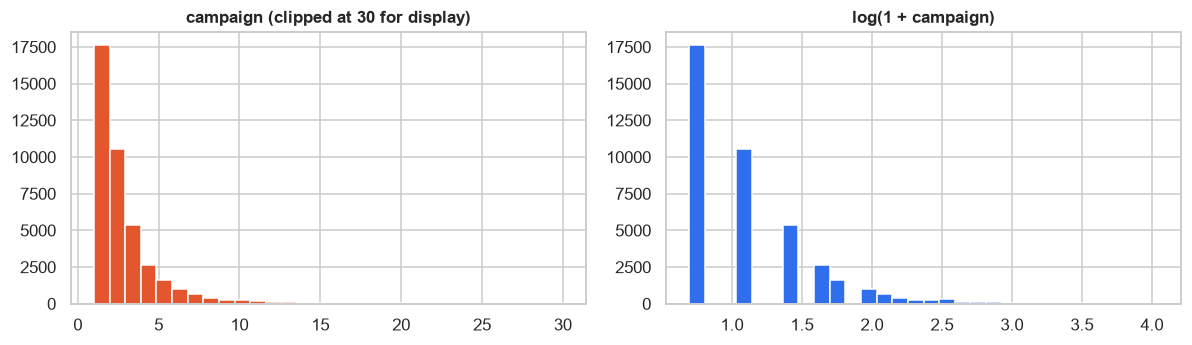

In [6]:
print(f"Skewness of campaign: {fx['campaign'].skew():.2f}  ->  of log(1 + campaign): {fx['campaign_log'].skew():.2f}  (0 = symmetric)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist(fx["campaign"].clip(upper=30), bins=30, color=C_WARN); ax[0].set_title("campaign (clipped at 30 for display)")
ax[1].hist(fx["campaign_log"], bins=30, color=C_MAIN); ax[1].set_title("log(1 + campaign)")
plt.tight_layout(); save_fig("prep_campaign_log")

### 4.2 Scaling
Numeric columns live on very different scales (age in tens, `previous` in single digits, the removed macro columns in thousands). **Distance- or gradient-based models** (logistic regression, MLP, SVM) are sensitive to this; **tree models are not**. **Decision:** standardise numbers (mean 0, standard deviation 1, learned on the training rows) only for the models that need it, through the `scale` switch of `build_pipeline`. Quick evidence on the logistic regression:

In [7]:
num_cols, _ = active_columns()
scale_tbl = pd.DataFrame({"std before scaling": fx[num_cols].std(), "range before scaling": fx[num_cols].max() - fx[num_cols].min()}).round(2)
display(scale_tbl.T)
rows = []
for scale in (False, True):
    f = fc_eval(build_pipeline(LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), scale=scale), X_train, y_train)
    rows.append({"scaled": scale, "forward-chaining PR-AUC": f["pr_auc"].mean(), "ROC-AUC": f["roc_auc"].mean()})
display(pd.DataFrame(rows).set_index("scaled").round(4))

,age,campaign,campaign_log,pdays,previous,was_contacted_before,education_ord
std before scaling,10.420,2.770,0.490,1.350,0.490,0.190,1.640
range before scaling,81.000,55.000,3.350,27.000,7.000,1.000,6.000


,forward-chaining PR-AUC,ROC-AUC
scaled,,
False,0.099,0.543
True,0.098,0.539


**Reading.** Without scaling the regularised logistic regression penalises columns unevenly (a column with a large numeric range is penalised differently from a 0/1 flag), so scaling is part of a *fair* linear baseline. On this data the metric itself does not improve (the table above shows it unchanged or marginally lower), so scaling is kept for correctness and stable optimisation, not for a score gain.

---
## 5 · Splitting: respecting time

**Issue (EDA §9).** The response rate and the client mix drift. A shuffled split would put calls from the same month in both training and test and report an optimistic score.

**Options:** stratified random split (named in the proposal) / chronological split. **Decision: chronological.** The earliest 80% of rows are the *training period*; a block of 500 rows follows as a **pilot** (the first labelled calls of the new period; never scored); everything after is the **test period**, held out entirely and used once, in notebook 05. Model selection inside the training period uses *forward-chaining* folds (train on the past, validate on the next block) in addition to ordinary stratified folds.

The proposal asked for a stratified split. Stratification is still used where it is harmless, inside the cross-validation folds of notebooks 03-04, and notebook 05 (section 5) **measures how much a stratified random split would have flattered the results**, which turns the deviation into evidence.

In [8]:
per = ec.reconstruct_periods(df)
cut, pend = sp["cut"], sp["pilot_end"]
def span(a, b): return f"{per['period'].iloc[a]} -> {per['period'].iloc[b - 1]}"
summary = describe_split(sp)
summary["calendar span"] = [span(0, cut), span(cut, pend), span(pend, len(df))]
summary["mean euribor3m"] = [df["euribor3m"].iloc[:cut].mean(), df["euribor3m"].iloc[cut:pend].mean(), df["euribor3m"].iloc[pend:].mean()]
summary["response_rate"] = 100 * summary["response_rate"]
display(summary.rename(columns={"response_rate": "response_rate_%"}).round(2))
print("A stratified random split would give every part a response rate of about", round(100 * sp["y_all"].mean(), 1), "%.")

,rows,subscribers,response_rate_%,calendar span,mean euribor3m
part,,,,,
train,32940,2100,6.380,2008-05 -> 2009-05,4.270
pilot,500,32,6.400,2009-05 -> 2009-05,1.290
test,7736,2507,32.410,2009-05 -> 2010-11,1.010


A stratified random split would give every part a response rate of about 11.3 %.


**Reading.** Training, pilot and test periods differ in response rate and in the economic setting. That is **not a flaw in the split; it is the reality the bank would face**, and the final evaluation must show how the model copes with it. Two things follow for later notebooks: ranking quality is judged **within time blocks** and raw probabilities are **re-anchored** to the recent base rate (notebook 06).

**Why "fit on the training rows only" matters, shown with numbers.** A statistic learned from the whole file differs from the one learned from the training period; using the whole-file value would leak the future.

In [9]:
fx_all, fx_tr = add_features(df), add_features(sp["X_train"])
leak_demo = pd.DataFrame({
    "median education_ord": [fx_tr["education_ord"].median(), fx_all["education_ord"].median()],
    "mean age": [fx_tr["age"].mean(), fx_all["age"].mean()],
    "mean campaign": [fx_tr["campaign"].mean(), fx_all["campaign"].mean()],
    "share cellular %": [100 * (fx_tr["contact"] == "cellular").mean(), 100 * (fx_all["contact"] == "cellular").mean()],
}, index=["learned from TRAINING rows (what the pipeline does)", "learned from the WHOLE file (leaks the future)"])
display(leak_demo.round(3))

,median education_ord,mean age,mean campaign,share cellular %
learned from TRAINING rows (what the pipeline does),4.000,40.027,2.672,57.350
learned from the WHOLE file (leaks the future),4.000,40.024,2.568,63.471


---
## 6 · Feature engineering: the families promised in the proposal

The initial submission (section 15, step 4) promised four engineered feature families. Rather than add them and hope, each is tested against the baseline pipeline on the **same forward-chaining and stratified folds**.

| Family | Columns added | Why a bank might expect it to help |
|---|---|---|
| job / education groups | `job_group`, `edu_group` | 12 job levels are sparse; broader groups may generalise |
| loan interaction | `debt_load` (0-2), `housing_loan` | clients with both loans may be more cash-constrained |
| quarter indicators | `quarter` | coarser seasonality than `month` |
| `pdays` recency + previous success | `pdays_recent`, `pdays_late`, `pdays_log`, `prev_success` | fresh contacts and past successes are the strongest history signal |

**Adoption rule, stated before looking at any number:** a family is adopted only if it **improves mean forward-chaining PR-AUC, in at least 3 of 4 folds, and does not lower the stratified-CV PR-AUC.** A feature that helps only on shuffled folds is probably exploiting the calendar rather than the client.

fc_pr_auc  fc_delta fc_folds_better  cv_pr_auc  cv_delta        verdict
model                   features                                                                                                
Logistic regression     baseline                             0.098     0.000             0/4      0.201     0.000              -
                        + job/education groups               0.097    -0.001             2/4      0.201    -0.001  keep baseline
                        + loan interaction                   0.098     0.000             3/4      0.201    -0.000  keep baseline
                        + quarter indicators                 0.096    -0.002             1/4      0.201     0.000  keep baseline
                        + pdays recency + prev. success      0.098    -0.000             0/4      0.200    -0.002  keep baseline
                        + all four families                  0.096    -0.002             2/4      0.199    -0.002  keep baseline
Hist. gradient boosting baseline                             0.088     0.000             0/4      0.209     0.000              -
                        + job/education groups               0.088     0.000             3/4      0.209    -0.000  keep baseline
                        + loan interaction                   0.085    -0.002             0/4      0.209     0.000  keep baseline
                        + quarter indicators                 0.086    -0.001             0/4      0.211     0.002  keep baseline
                        + pdays recency + prev. success      0.088     0.000             0/4      0.210     0.001  keep baseline
                        + all four families                  0.084    -0.004             1/4      0.211     0.003  keep baseline

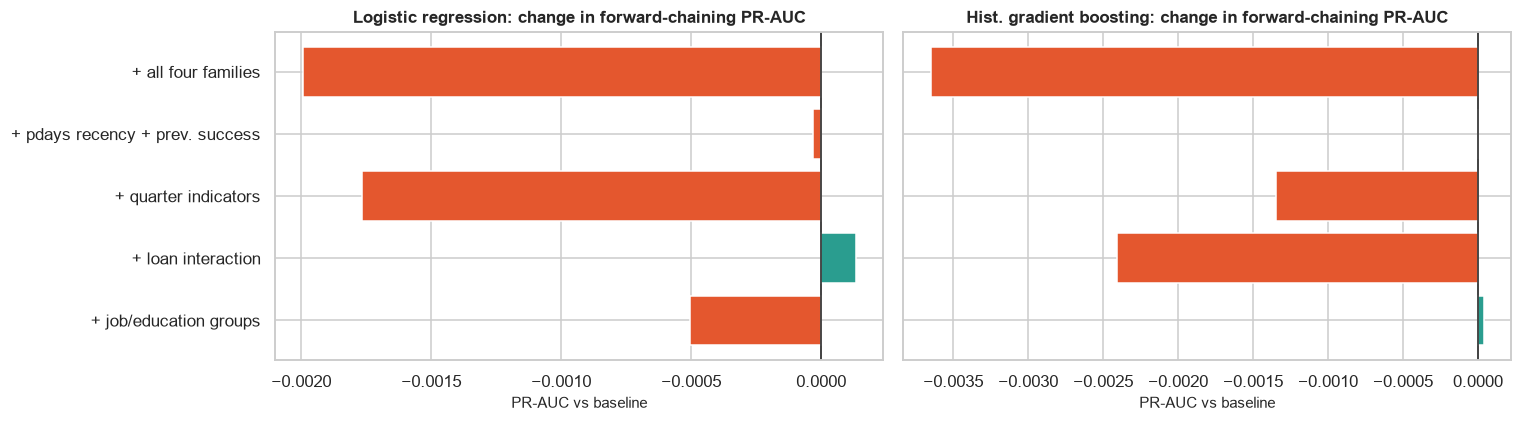

Families that pass the rule for at least one model: none


In [10]:
fe_configs = {"baseline": []}
fe_configs.update({f"+ {k}": [k] for k in FE_GROUPS})
fe_configs["+ all four families"] = list(FE_GROUPS)
FAM_MODELS = {"Logistic regression": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True),
              "Hist. gradient boosting": (lambda: hgb(learning_rate=0.06, max_iter=200, class_weight="balanced"), False)}
cv_folds = 3 if FAST else 5
fe_fc, fe_cv = {}, {}
for mname, (factory, scale) in FAM_MODELS.items():
    for cname, groups in fe_configs.items():
        p = family_pipeline(factory(), groups, scale)
        fe_fc[(mname, cname)] = fc_eval(p, X_train, y_train)
        fe_cv[(mname, cname)] = cv_eval(p, X_train, y_train, cv_folds)

rows = []
for (mname, cname), f in fe_fc.items():
    f0, c0 = fe_fc[(mname, "baseline")], fe_cv[(mname, "baseline")]
    d = f["pr_auc"] - f0["pr_auc"]
    dc = fe_cv[(mname, cname)]["pr_auc"].mean() - c0["pr_auc"].mean()
    adopt = cname != "baseline" and d.mean() > 0 and (d > 0).sum() >= 3 and dc >= 0
    rows.append(dict(model=mname, features=cname, fc_pr_auc=f["pr_auc"].mean(), fc_delta=d.mean(),
                     fc_folds_better=f"{int((d > 0).sum())}/{len(d)}", cv_pr_auc=fe_cv[(mname, cname)]["pr_auc"].mean(), cv_delta=dc,
                     verdict="ADOPT" if adopt else ("-" if cname == "baseline" else "keep baseline")))
fe_table = pd.DataFrame(rows).set_index(["model", "features"])
display(fe_table.round(4))
fe_table.to_csv(TABLES_DIR / "preprocessing_feature_families.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, mname in zip(ax, FAM_MODELS):
    t = fe_table.loc[mname].drop("baseline")
    a.barh(t.index, t["fc_delta"], color=[C_OK if v > 0 else C_WARN for v in t["fc_delta"]]); a.axvline(0, color="k", lw=1)
    a.set_title(f"{mname}: change in forward-chaining PR-AUC"); a.set_xlabel("PR-AUC vs baseline")
plt.tight_layout(); save_fig("prep_feature_families")
adopted = sorted({c.replace("+ ", "") for (_, c), r in fe_table["verdict"].items() if r == "ADOPT" and not c.startswith("+ all")})
print("Families that pass the rule for at least one model:", adopted or "none")

**Decision rule in action.** If the table shows `ADOPT` for a family, list it in `ADOPTED_FAMILIES` in `src/config.py` (the one switch every later notebook reads) and re-run notebooks 03 onward. If every row says `keep baseline`, the baseline pipeline stays; this is a legitimate, evidence-based outcome, and it should be reported as such. The baseline columns already contain the information the families re-express (tree models can learn thresholds on `pdays`; `month` already covers quarters), which is the usual reason such families add little.

---
## 7 · Leakage and realism audit

### 7.1 Why `duration` must go: measured, not assumed
The same model, the same folds, with and without `duration`. If adding it makes the model look far better, that is not skill: it is information from the *future* of the call.

,roc_auc,pr_auc,lift_at_budget,recall_at_budget
"WITH duration (leaky, not deployable)",0.953 +/- 0.002,0.527 +/- 0.013,4.752 +/- 0.043,0.95 +/- 0.009
WITHOUT duration (honest),0.671 +/- 0.003,0.202 +/- 0.009,2.169 +/- 0.015,0.434 +/- 0.003


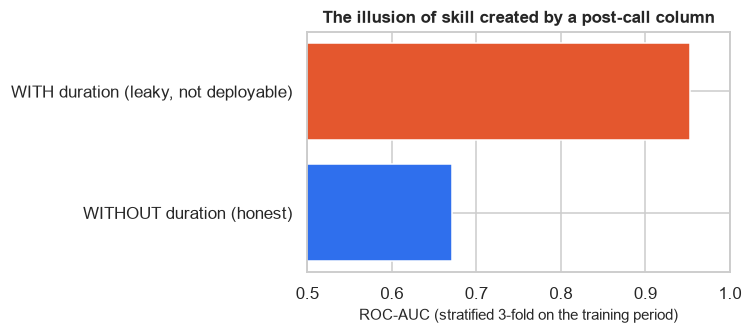

In [11]:
leak = {
    "WITH duration (leaky, not deployable)": cv_eval(build_pipeline(hgb(), scale=False, include_duration=True), X_train, y_train, 3),
    "WITHOUT duration (honest)": cv_eval(build_pipeline(hgb(), scale=False), X_train, y_train, 3),
}
leak_mean, leak_txt = summarise(leak)
display(leak_txt[["roc_auc", "pr_auc", "lift_at_budget", "recall_at_budget"]])
leak_mean.to_csv(TABLES_DIR / "preprocessing_leakage_duration.csv")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(list(leak_mean.index)[::-1], leak_mean["roc_auc"][::-1], color=[C_MAIN, C_WARN]); ax.set_xlim(0.5, 1); ax.set_xlabel("ROC-AUC (stratified 3-fold on the training period)")
ax.set_title("The illusion of skill created by a post-call column")
plt.tight_layout(); save_fig("prep_leakage_duration")

**Reading.** The gap between the two rows is created entirely by information that does not exist when the call list is built. A campaign manager cannot know how long a call *will* last. In the group's first run the leaky model reached a ROC-AUC of about 0.95 against about 0.67 for the honest one. Only the honest model answers the business question, so `duration` is never in `NUM_COLS`, and a test (`tests/test_preprocessing.py`) fails if it ever appears in a deployable pipeline.

### 7.2 A realism check for the grey-zone column `campaign`
`campaign` counts the calls to a client in this campaign, including the last one (EDA §2, §8). Clients who agree stop being called; clients who refuse are called again, so the final count partly records the outcome. If the model's skill depended mostly on this column, it would be *looking at the answer* in a mild form. Test: remove `campaign` and `campaign_log` and compare on forward-chaining folds.

**Rule fixed in advance:** if removing the column changes forward-chaining PR-AUC by **less than one standard deviation across folds**, the model is not relying on it, so it stays (as in the proposal) with the caveat documented. If removing it *improves* or barely changes the score, the group should seriously consider dropping it.

In [12]:
rows = []
for mname, (factory, scale) in FAM_MODELS.items():
    with_c = fc_eval(build_pipeline(factory(), scale=scale), X_train, y_train)
    without = fc_eval(build_pipeline(factory(), scale=scale, exclude=("campaign", "campaign_log")), X_train, y_train)
    d = (without["pr_auc"] - with_c["pr_auc"])
    sd = with_c["pr_auc"].std()
    rows.append(dict(model=mname, pr_auc_with_campaign=with_c["pr_auc"].mean(), pr_auc_without=without["pr_auc"].mean(),
                     change_when_removed=d.mean(), fold_sd=sd,
                     verdict="not relying on campaign: keep, document caveat" if abs(d.mean()) < sd else ("removing it HURTS: campaign carries signal (check reverse causality)" if d.mean() < 0 else "removing it HELPS: consider dropping campaign")))
campaign_test = pd.DataFrame(rows).set_index("model")
display(campaign_test.round(4))
campaign_test.to_csv(TABLES_DIR / "preprocessing_campaign_sensitivity.csv")

,pr_auc_with_campaign,pr_auc_without,change_when_removed,fold_sd,verdict
model,,,,,
Logistic regression,0.098,0.098,0.000,0.083,"not relying on campaign: keep, document caveat"
Hist. gradient boosting,0.088,0.084,-0.004,0.062,"not relying on campaign: keep, document caveat"


---
## 8 · The final pipeline and its automatic checks

`build_pipeline` assembles every decision above. We fit it on the **training period only** and then verify the properties that matter. Each check is an assertion: the notebook stops if one fails.

In [13]:
final_pipe = build_pipeline(LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), scale=True).fit(X_train, y_train)
pre = final_pipe.named_steps["prep"]
Z_train = final_pipe[:-1].transform(X_train)
Z_test = final_pipe[:-1].transform(X_test)

# 1. nothing missing reaches the model
assert not np.isnan(Z_train).any() and not np.isnan(Z_test).any(); print("OK  no missing values after preprocessing (train or test)")
# 2. same columns for train and test
assert Z_train.shape[1] == Z_test.shape[1]; print(f"OK  {Z_train.shape[1]} model inputs, identical for train and test")
# 3. leakage columns are absent
names = list(pre.get_feature_names_out())
assert not any("duration" in n for n in names); print("OK  `duration` is not a model input")
if EXCLUDE_MACRO:
    assert not any(any(m in n for m in MACRO_COLS) for n in names); print("OK  macro indicators are not model inputs (EXCLUDE_MACRO = True)")
# 4. the imputer learned its medians from TRAINING rows only
med = pre.named_transformers_["num"].named_steps["imp"].statistics_
expected = add_features(X_train)[active_columns()[0]].median().values
assert np.allclose(med, expected, equal_nan=True); print("OK  imputer medians equal the TRAINING medians")
# 5. an unseen category does not crash the pipeline
odd = X_test.iloc[:3].copy(); odd["job"] = "astronaut"
final_pipe.predict_proba(odd); print("OK  unseen category ('astronaut') is handled")
# 6. standardised numeric columns have mean ~0 and sd ~1 on training data
n_num = len(active_columns()[0])
assert np.allclose(Z_train[:, :n_num].mean(0), 0, atol=1e-6); print("OK  scaled numeric columns are centred on the training data")

OK  no missing values after preprocessing (train or test)
OK  52 model inputs, identical for train and test
OK  `duration` is not a model input
OK  macro indicators are not model inputs (EXCLUDE_MACRO = True)
OK  imputer medians equal the TRAINING medians
OK  unseen category ('astronaut') is handled
OK  scaled numeric columns are centred on the training data


In [14]:
flog = feature_log(final_pipe, X_train)
flog.to_csv(TABLES_DIR / "final_feature_list.csv", index=False)
print(f"{len(flog)} model inputs built from {flog['source_column'].nunique()} source columns")
display(flog.groupby("source_column").agg(inputs=("model_input", "size"), treatment=("treatment", "first")).sort_values("inputs", ascending=False))
display(flog.head(12))

52 model inputs built from 16 source columns


,inputs,treatment
source_column,,
job,12,one-hot indicator
month,9,one-hot indicator
day_of_week,5,one-hot indicator
marital,4,one-hot indicator
loan,3,one-hot indicator
default,3,one-hot indicator
housing,3,one-hot indicator
poutcome,3,one-hot indicator
contact,2,one-hot indicator


,model_input,source_column,treatment,mean_after,std_after
0,num__age,age,median-imputed + standardised,-0.000,1.000
1,num__campaign,campaign,median-imputed + standardised,-0.000,1.000
2,num__campaign_log,campaign_log,median-imputed + standardised,0.000,1.000
3,num__pdays,pdays,median-imputed + standardised,0.000,1.000
4,num__previous,previous,median-imputed + standardised,0.000,1.000
5,num__was_contacted_before,was_contacted_before,median-imputed + standardised,-0.000,1.000
6,num__education_ord,education_ord,median-imputed + standardised,-0.000,1.000
7,num__missingindicator_education_ord,education_ord,missing-value indicator (1 = was 'unknown'),0.000,1.000
8,cat__job_admin.,job,one-hot indicator,0.244,0.430
9,cat__job_blue-collar,job,one-hot indicator,0.242,0.428


---
## 9 · Preprocessing decision log

| # | Issue | Options considered | Decision | Evidence |
|---|---|---|---|---|
| P1 | 12 duplicate rows | keep / drop | Drop, keep first and original order | §3.1 |
| P2 | `unknown` in categorical columns | own category / mode imputation / drop rows | Own category (verdict printed in §3.2) | §3.2 forward-chaining test, EDA 3.4 |
| P3 | `unknown` education | one-hot / ordinal | Ordinal; `unknown` → NaN → training median + missing indicator | §3.2 |
| P4 | `pdays = 999` | leave / impute / flag + 0 | Flag `was_contacted_before`, placeholder → 0 | §3.3, EDA 3.6 |
| P5 | Skewed `campaign` | leave / clip / log | Keep + `campaign_log` | §4.1 |
| P6 | Scales differ | none / standardise | Standardise for linear, neural, SVM models only | §4.2 |
| P7 | Drift over time | stratified random / chronological | Chronological train / pilot / test; forward-chaining CV | §5, EDA §9 |
| P8 | Proposal feature families | baseline / each / all | Adopt only if ≥ 3 of 4 forward-chaining folds improve and CV does not fall (verdict in §6) | §6 |
| P9 | `duration` | keep / drop | Drop: known only after the call | §7.1 |
| P10 | `campaign` reverse causality | keep / drop | Keep, caveat; sensitivity test (verdict in §7.2) | §7.2 |
| P11 | Macro indicators | include / exclude | Exclude by default; tested in notebook 03 §5 | EDA §10 |
| P12 | Leakage control | manual / structural | Every learned step inside one `Pipeline`; asserted in §8 and `tests/` | §8 |

**Hand-off.** Notebooks 03-08 import `build_pipeline` and the split from `src/` and **do not re-implement any preprocessing**. The feature list is saved to `reports/tables/final_feature_list.csv`; the group-level write-up of these decisions is `docs/preprocessing_log.md`.